# Clustering

## Imports, choix d'une décennie et chargement des fichiers

In [1]:
import collections
import os
import string
import sys

import pandas as pd
from nltk import word_tokenize
from nltk.corpus import stopwords
from pprint import pprint
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cosine

In [2]:
import nltk

nltk.download('punkt')
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/alexiawaucquez/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/alexiawaucquez/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [9]:
data_path = "../txt/"

In [10]:
DECADE = '1910'

In [11]:
files = [f for f in sorted(os.listdir(data_path)) if f"_{DECADE[:-1]}" in f]

In [12]:
texts = [open(data_path + f, "r", encoding="utf-8").read() for f in files]

## Vectorisation

In [13]:
# Création d'une fonction de pré-traitement
def preprocessing(text, stem=True):
    """ Tokenize text and remove punctuation """
    text = text.translate(string.punctuation)
    tokens = word_tokenize(text)
    return tokens

In [14]:
vectorizer = TfidfVectorizer(
    tokenizer=preprocessing,
    stop_words=stopwords.words('french'),
    max_df=0.5,
    min_df=0.1,
    lowercase=True)

In [15]:
tfidf_vectors = vectorizer.fit_transform(texts)

/Users/alexiawaucquez/tac/.venv/lib/python3.11/site-packages/sklearn/feature_extraction/text.py:527: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


## Clustering

In [16]:
N_CLUSTERS = 5

In [17]:
km_model = KMeans(n_clusters=N_CLUSTERS)

In [18]:
clusters = km_model.fit_predict(tfidf_vectors)

In [19]:
clustering = collections.defaultdict(list)

for idx, label in enumerate(clusters):
    clustering[label].append(files[idx])

In [20]:
pprint(dict(clustering))

{np.int32(0): ['KB_JB838_1910-01-22_01-00004.txt',
               'KB_JB838_1910-02-09_01-00004.txt',
               'KB_JB838_1910-03-05_01-00008.txt',
               'KB_JB838_1910-03-28_01-00004.txt',
               'KB_JB838_1910-04-02_01-00004.txt',
               'KB_JB838_1910-04-29_01-00004.txt',
               'KB_JB838_1910-06-01_01-00004.txt',
               'KB_JB838_1910-07-02_01-00004.txt',
               'KB_JB838_1910-08-18_01-00005.txt',
               'KB_JB838_1910-09-18_01-00009.txt',
               'KB_JB838_1910-11-07_01-00005.txt',
               'KB_JB838_1910-11-27_01-00008.txt',
               'KB_JB838_1910-12-01_01-00008.txt',
               'KB_JB838_1911-01-23_01-00004.txt',
               'KB_JB838_1911-02-08_01-00008.txt',
               'KB_JB838_1911-02-25_01-00006.txt',
               'KB_JB838_1911-04-10_01-00004.txt',
               'KB_JB838_1911-05-19_01-00010.txt',
               'KB_JB838_1911-06-11_01-00011.txt',
               'KB_JB838_1911-0

In [21]:
pca = PCA(n_components=2)
reduced_vectors = pca.fit_transform(tfidf_vectors.toarray())

In [22]:
reduced_vectors[:10]

array([[ 0.10682943, -0.53231762],
       [-0.33401337,  0.12721164],
       [ 0.2234679 , -0.33813834],
       [ 0.6005316 ,  0.30108023],
       [ 0.41518416, -0.00272617],
       [-0.29112631,  0.10829669],
       [-0.25028559,  0.03569582],
       [-0.12982622, -0.14191043],
       [-0.28893612,  0.07482188],
       [-0.26858278,  0.05405482]])

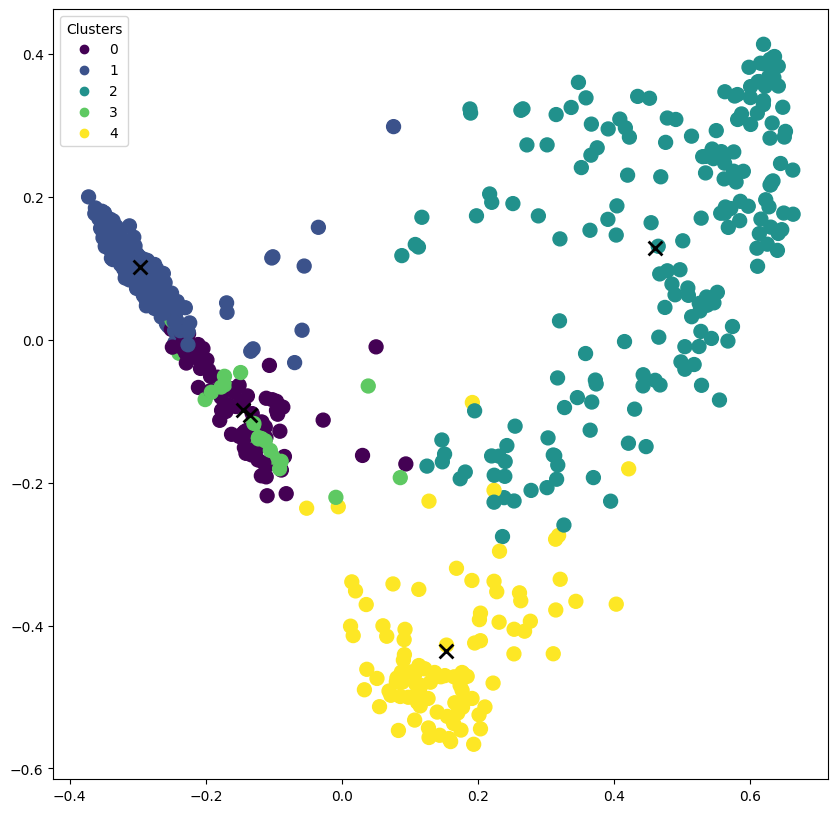

In [23]:
x_axis = reduced_vectors[:, 0]
y_axis = reduced_vectors[:, 1]

plt.figure(figsize=(10,10))
scatter = plt.scatter(x_axis, y_axis, s=100, c=clusters)

# Ajouter les centroïdes
centroids = pca.transform(km_model.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1],  marker = "x", s=100, linewidths = 2, color='black')

# Ajouter la légende
plt.legend(handles=scatter.legend_elements()[0], labels=set(clusters), title="Clusters")